# RPC Automatic Checkout with YOLO11

This notebook builds a complete retail checkout system with PyTorch, Ultralytics YOLO and OpenCV. It uses the multi-product RPC checkout scenes from the original validation and test sets, creates leakage-aware grouped train, validation and test splits, trains or loads two detectors, evaluates detection and checkout accuracy, and produces five English checkout examples.


## 1. Environment setup

In [1]:
# Install the libraries used for training evaluation and visualization
%pip install -q ultralytics opencv-python-headless pandas matplotlib seaborn pyyaml tqdm scikit-learn transformers sentencepiece

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the tools used throughout the experiment
# Keep the random state fixed so the split and examples remain reproducible
import json
import os
import random
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
from ultralytics import YOLO

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.8.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4090


## 2. Experiment configuration

Both models use the same custom multi-product split and training settings. The baseline uses YOLO11n while the main model uses the larger YOLO11s architecture.

In [3]:
# Store all experiment settings in one place for clear reporting
# Keep checkpoints and generated figures on the persistent AutoDL disk
SEED = 42
ROOT = Path("/root/autodl-tmp/retail_product_checkout")
PREPARE_SCRIPT = Path("/root/autodl-tmp/prepare_metadata.py")
CUSTOM_ROOT = ROOT / "custom_checkout_dataset"
RUNS_ROOT = ROOT / "runs/custom_split_test"
FIGURES_ROOT = ROOT / "figures/custom_split"
EXAMPLES_ROOT = RUNS_ROOT / "checkout_examples"

BASELINE_RUN_NAME = "custom_yolo11n_baseline"
MAIN_RUN_NAME = "yolo11s_checkout_split"
BASELINE_SOURCE = "yolo11n.pt"
MAIN_SOURCE = "yolo11s.pt"

EPOCHS = 10
IMGSZ = 640
BATCH = 64
INFERENCE_BATCH = 16
WORKERS = 8
DEVICE = 0 if torch.cuda.is_available() else "cpu"
CONFIDENCE_CANDIDATES = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
EXAMPLES_ROOT.mkdir(parents=True, exist_ok=True)

## 3. Prepare metadata

This step creates `product_prices.csv` and `product_name_mapping.csv`. Existing translations are reused by the preparation script.

In [4]:
# Create the English product names and simulated price table before training
# The preparation script reuses metadata files that already exist
if not PREPARE_SCRIPT.exists():
    raise FileNotFoundError(f"Preparation script not found: {PREPARE_SCRIPT}")

%run /root/autodl-tmp/prepare_metadata.py

Loading product metadata...
Creating product price table...
Creating Chinese and English product name mapping...
All MarianMT translations already exist.

Preparation summary
------------------------------------------------------------
Product classes:       17
Product SKUs:          200
Unique barcodes:       200
Missing prices:        0
Missing translations:  0
Minimum price:         ¥1.50
Maximum price:         ¥76.00
Price file:            /root/autodl-tmp/retail_product_checkout/product_prices.csv
Name mapping file:     /root/autodl-tmp/retail_product_checkout/product_name_mapping.csv

Price table preview
 category_id      sku_name   sku_class       barcode  unit_price currency             price_source
           1 1_puffed_food puffed_food 6909409012031        14.5      CNY simulated_by_class_range
           2 2_puffed_food puffed_food 6901845043112         5.0      CNY simulated_by_class_range
           3 3_puffed_food puffed_food 6909409012024         3.0      CNY simulated_b

## 4. Load and inspect the multi-product data

The official RPC training set contains mostly isolated product photographs. This experiment instead combines the official validation and test checkout scenes, then creates a new grouped 80 percent, 10 percent and 10 percent split. These custom results must not be compared directly with the official RPC benchmark.

In [5]:
# Check only the files required by the custom multi-product experiment
# Stop early when a source folder or metadata file is missing
required_paths = [
    ROOT / "val2019",
    ROOT / "test2019",
    ROOT / "instances_val2019.json",
    ROOT / "instances_test2019.json",
    ROOT / "product_prices.csv",
    ROOT / "product_name_mapping.csv",
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError("Missing required paths:\n" + "\n".join(missing_paths))

def group_key(file_name):
    # Break the timestamp based file name into fields
    parts = Path(file_name).stem.split("-")
    # Place nearby captures from the same camera into one group
    if len(parts) >= 5 and parts[2].isdigit():
        return f"{parts[0]}-{parts[1]}-{int(parts[2]) // 2}-{parts[-1]}"
    return Path(file_name).stem

def load_checkout_records():
    # Store one combined record for every checkout image
    records = []
    categories = None

    # Read both original multi-product annotation files
    for source_split in ["val", "test"]:
        annotation_path = ROOT / f"instances_{source_split}2019.json"
        with annotation_path.open("r", encoding="utf-8") as file:
            data = json.load(file)

        # Read the shared SKU list once and preserve category order
        if categories is None:
            categories = sorted(data["categories"], key=lambda item: item["id"])

        # Index annotations by image for efficient record creation
        annotations_by_image = defaultdict(list)
        for annotation in data["annotations"]:
            annotations_by_image[annotation["image_id"]].append(annotation)

        # Attach image metadata annotations and the capture group
        for image in data["images"]:
            records.append({
                "source": ROOT / f"{source_split}2019" / image["file_name"],
                "file_name": image["file_name"],
                "width": image["width"],
                "height": image["height"],
                "annotations": annotations_by_image[image["id"]],
                "group": group_key(image["file_name"]),
            })

    return records, categories

records, categories = load_checkout_records()
print("Multi-product images:", len(records))
print("Product instances:", sum(len(record["annotations"]) for record in records))
print("SKU classes:", len(categories))

Multi-product images: 30000
Product instances: 367935
SKU classes: 200


## 5. Create grouped train, validation and test splits

Images sharing the same derived capture group remain in one split. This reduces leakage from adjacent photographs of the same checkout arrangement.

In [6]:
# Keep related capture groups in the same split to reduce scene leakage
# Reserve ten percent of the images for validation and ten percent for testing
def split_checkout_records(records):
    # Build parallel arrays for sample indices and capture groups
    indices = np.arange(len(records))
    groups = np.array([record["group"] for record in records])

    # Select eighty percent of the capture groups for training
    first_split = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=SEED)
    train_indices, remaining_indices = next(first_split.split(indices, groups=groups))

    # Divide the remaining groups equally between validation and test
    remaining_groups = groups[remaining_indices]
    second_split = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=SEED)
    validation_positions, test_positions = next(
        second_split.split(remaining_indices, groups=remaining_groups)
    )

    # Convert the selected indices back into image records
    return {
        "train": [records[index] for index in train_indices],
        "val": [records[remaining_indices[position]] for position in validation_positions],
        "test": [records[remaining_indices[position]] for position in test_positions],
    }

splits = split_checkout_records(records)

# Summarize the size and density of each custom split
split_summary = pd.DataFrame([
    {
        "Split": split_name,
        "Images": len(split_records),
        "Instances": sum(len(record["annotations"]) for record in split_records),
        "Groups": len({record["group"] for record in split_records}),
        "Mean products per image": np.mean(
            [len(record["annotations"]) for record in split_records]
        ),
    }
    for split_name, split_records in splits.items()
])

display(split_summary.round(2))

# Confirm that no derived capture group appears in two splits
group_sets = {
    split_name: {record["group"] for record in split_records}
    for split_name, split_records in splits.items()
}
assert group_sets["train"].isdisjoint(group_sets["val"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["val"].isdisjoint(group_sets["test"])

,Split,Images,Instances,Groups,Mean products per image
0,train,23985,294410,10160,12.27
1,val,2970,36568,1270,12.31
2,test,3045,36957,1270,12.14


## 6. Convert COCO annotations to YOLO format

Hard links avoid duplicating the image data. Existing links and labels are reused safely.

In [7]:
# Convert each COCO bounding box to the normalized YOLO label format
# Use hard links so the large image collection is not copied to another folder
def build_yolo_dataset(splits, categories):
    # YOLO class indices start at zero while RPC category identifiers start at one
    category_to_yolo = {
        category["id"]: index for index, category in enumerate(categories)
    }

    # Create a matching image and label directory for every split
    for split_name, split_records in splits.items():
        image_directory = CUSTOM_ROOT / "images" / split_name
        label_directory = CUSTOM_ROOT / "labels" / split_name
        image_directory.mkdir(parents=True, exist_ok=True)
        label_directory.mkdir(parents=True, exist_ok=True)

        # Convert every image record without copying the source image
        for record in tqdm(split_records, desc=f"Preparing {split_name}"):
            target_image = image_directory / record["file_name"]
            # Reuse an existing hard link when the notebook is run again
            if not target_image.exists():
                os.link(record["source"], target_image)

            # Translate each absolute COCO box into normalized YOLO values
            label_lines = []
            for annotation in record["annotations"]:
                x, y, width, height = annotation["bbox"]
                x_center = (x + width / 2) / record["width"]
                y_center = (y + height / 2) / record["height"]
                normalized_width = width / record["width"]
                normalized_height = height / record["height"]
                class_index = category_to_yolo[annotation["category_id"]]
                label_lines.append(
                    f"{class_index} {x_center:.6f} {y_center:.6f} "
                    f"{normalized_width:.6f} {normalized_height:.6f}"
                )

            # Write one text label file beside the linked image
            label_path = label_directory / f"{Path(record['file_name']).stem}.txt"
            label_path.write_text("\n".join(label_lines), encoding="utf-8")

    # Save the dataset paths and ordered class names for Ultralytics
    configuration = {
        "path": str(CUSTOM_ROOT),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": {
            index: category["name"] for index, category in enumerate(categories)
        },
    }

    with (CUSTOM_ROOT / "data.yaml").open("w", encoding="utf-8") as file:
        yaml.safe_dump(configuration, file, sort_keys=False, allow_unicode=True)

    return category_to_yolo

category_to_yolo = build_yolo_dataset(splits, categories)
print("YOLO configuration:", CUSTOM_ROOT / "data.yaml")

Preparing train:   0%|          | 0/23985 [00:00<?, ?it/s]

Preparing val:   0%|          | 0/2970 [00:00<?, ?it/s]

Preparing test:   0%|          | 0/3045 [00:00<?, ?it/s]

YOLO configuration: /root/autodl-tmp/retail_product_checkout/custom_checkout_dataset/data.yaml


## 7. Inspect converted ground-truth annotations

The boxes in this section come from the RPC JSON annotations after conversion. They are not model predictions.

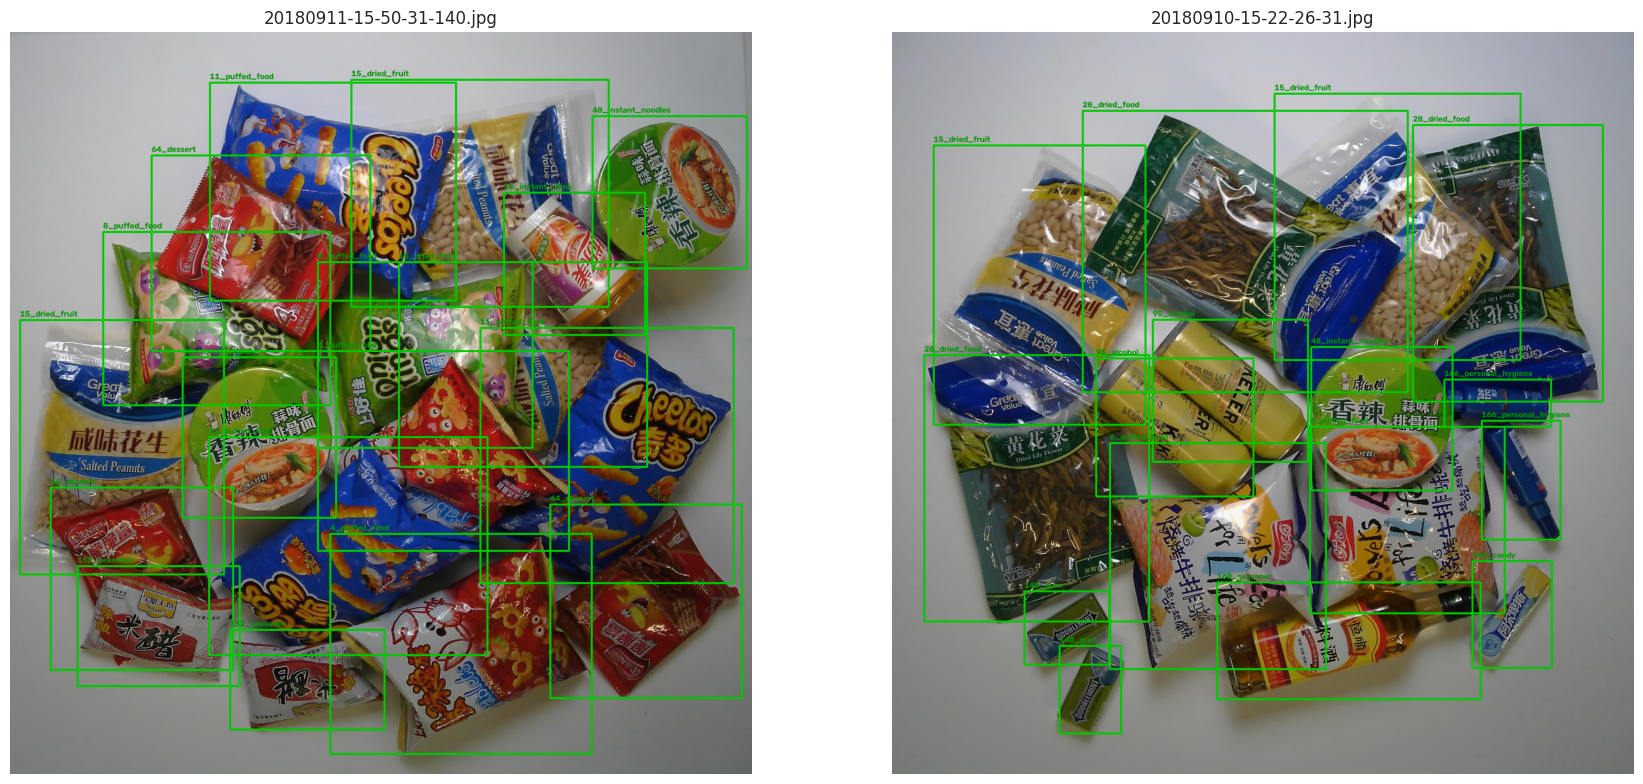

In [8]:
# Draw two converted labels as a visual check before model training
# These green boxes come from the dataset annotations rather than model predictions
def draw_ground_truth(record, category_to_yolo):
    # Load the original image without changing its resolution
    image = cv2.imread(str(record["source"]))
    # Draw every dataset box with its RPC SKU label
    for annotation in record["annotations"]:
        x, y, width, height = map(int, annotation["bbox"])
        class_index = category_to_yolo[annotation["category_id"]]
        label = categories[class_index]["name"]
        cv2.rectangle(image, (x, y), (x + width, y + height), (0, 200, 0), 4)
        cv2.putText(
            image,
            label,
            (x, max(25, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 150, 0),
            2,
            cv2.LINE_AA,
        )
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Use a fixed sample so repeated notebook runs show the same images
inspection_records = random.Random(SEED).sample(splits["train"], 2)
figure, axes = plt.subplots(1, 2, figsize=(18, 8))
for axis, record in zip(axes, inspection_records):
    axis.imshow(draw_ground_truth(record, category_to_yolo))
    axis.set_title(record["file_name"])
    axis.axis("off")
plt.tight_layout()
plt.show()

## 8. Training protocol

A checkpoint is loaded whenever `best.pt` already exists. Training starts only when that model checkpoint is missing.

In [9]:
# Record the shared settings used for a fair model comparison
# Only the YOLO model size changes between the baseline and main experiment
training_configuration = pd.DataFrame([
    {"Parameter": "Framework", "Value": "PyTorch and Ultralytics YOLO"},
    {"Parameter": "Baseline", "Value": "YOLO11n"},
    {"Parameter": "Main model", "Value": "YOLO11s"},
    {"Parameter": "Optimizer", "Value": "AdamW"},
    {"Parameter": "Initial learning rate", "Value": 0.001},
    {"Parameter": "Batch size", "Value": BATCH},
    {"Parameter": "Image size", "Value": IMGSZ},
    {"Parameter": "Epochs", "Value": EPOCHS},
    {"Parameter": "Detection losses", "Value": "Box, classification and DFL"},
    {"Parameter": "Main metric", "Value": "Test cAcc and mAP@0.5:0.95"},
])
display(training_configuration)

,Parameter,Value
0,Framework,PyTorch and Ultralytics YOLO
1,Baseline,YOLO11n
2,Main model,YOLO11s
3,Optimizer,AdamW
4,Initial learning rate,0.001
5,Batch size,64
6,Image size,640
7,Epochs,10
8,Detection losses,"Box, classification and DFL"
9,Main metric,Test cAcc and mAP@0.5:0.95


In [10]:
# Reuse a completed checkpoint whenever its best weight file is available
# Start training only when the requested checkpoint does not exist
def train_or_load(model_source, run_name):
    # Derive the checkpoint path from the stable experiment name
    weights_path = RUNS_ROOT / run_name / "weights" / "best.pt"

    # Loading here prevents accidental retraining after a completed run
    if weights_path.exists():
        print(f"Existing weights found: {weights_path}")
        print("Training skipped.")
        return YOLO(str(weights_path)), weights_path

    # Start from public COCO pretrained weights when no checkpoint exists
    print(f"No checkpoint found. Training {run_name}.")
    model = YOLO(model_source)
    # Train both model sizes with the same data and hyperparameters
    model.train(
        data=str(CUSTOM_ROOT / "data.yaml"),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        workers=WORKERS,
        device=DEVICE,
        optimizer="AdamW",
        lr0=0.001,
        patience=0,
        amp=False,
        cache=False,
        project=str(RUNS_ROOT),
        name=run_name,
        exist_ok=True,
        plots=True,
        verbose=False,
        seed=SEED,
    )

    # Verify that Ultralytics saved the checkpoint expected by later cells
    if not weights_path.exists():
        raise FileNotFoundError(f"Training did not create {weights_path}")

    return YOLO(str(weights_path)), weights_path

baseline_model, baseline_weights = train_or_load(BASELINE_SOURCE, BASELINE_RUN_NAME)
main_model, main_weights = train_or_load(MAIN_SOURCE, MAIN_RUN_NAME)

Existing weights found: /root/autodl-tmp/retail_product_checkout/runs/custom_split_test/custom_yolo11n_baseline/weights/best.pt
Training skipped.
Existing weights found: /root/autodl-tmp/retail_product_checkout/runs/custom_split_test/yolo11s_checkout_split/weights/best.pt
Training skipped.


## 9. Training curves

Loss curves describe optimization on the training and validation data. Precision, recall and mAP curves describe validation performance after each epoch.

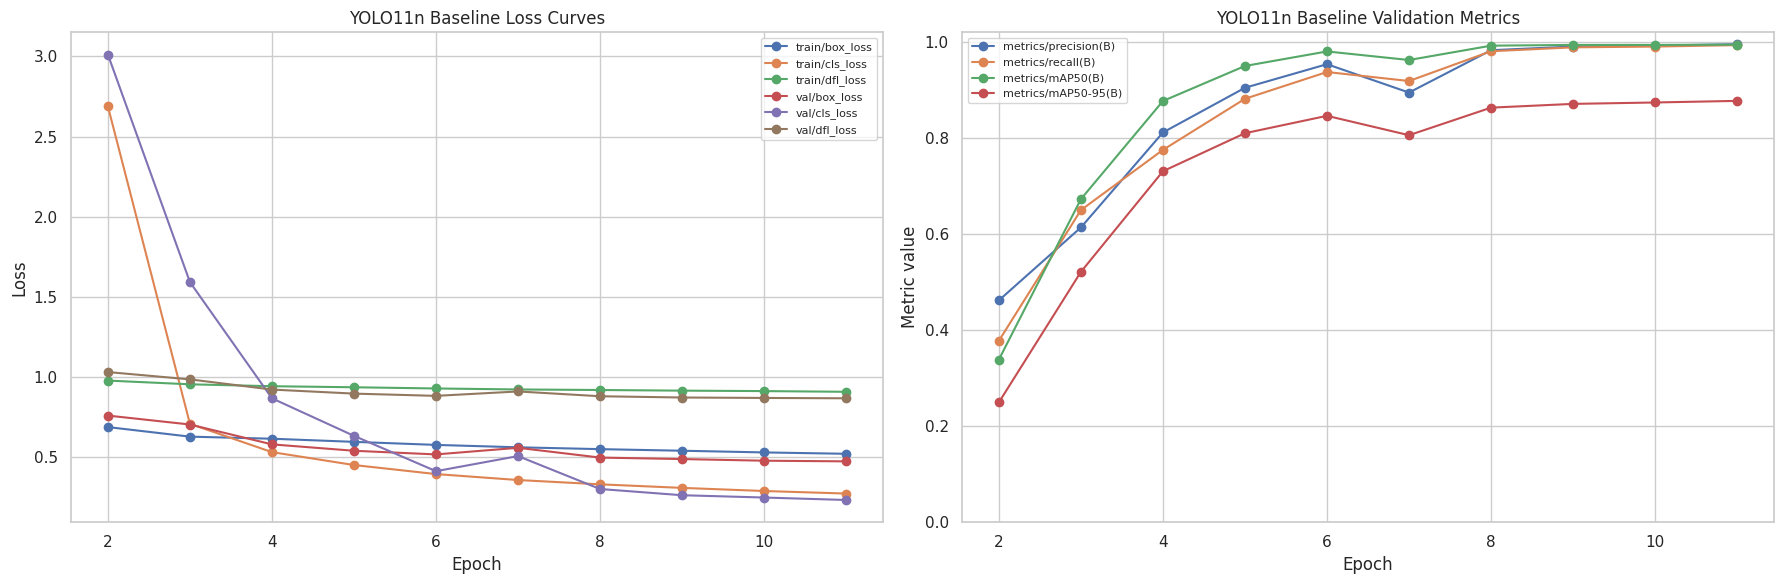

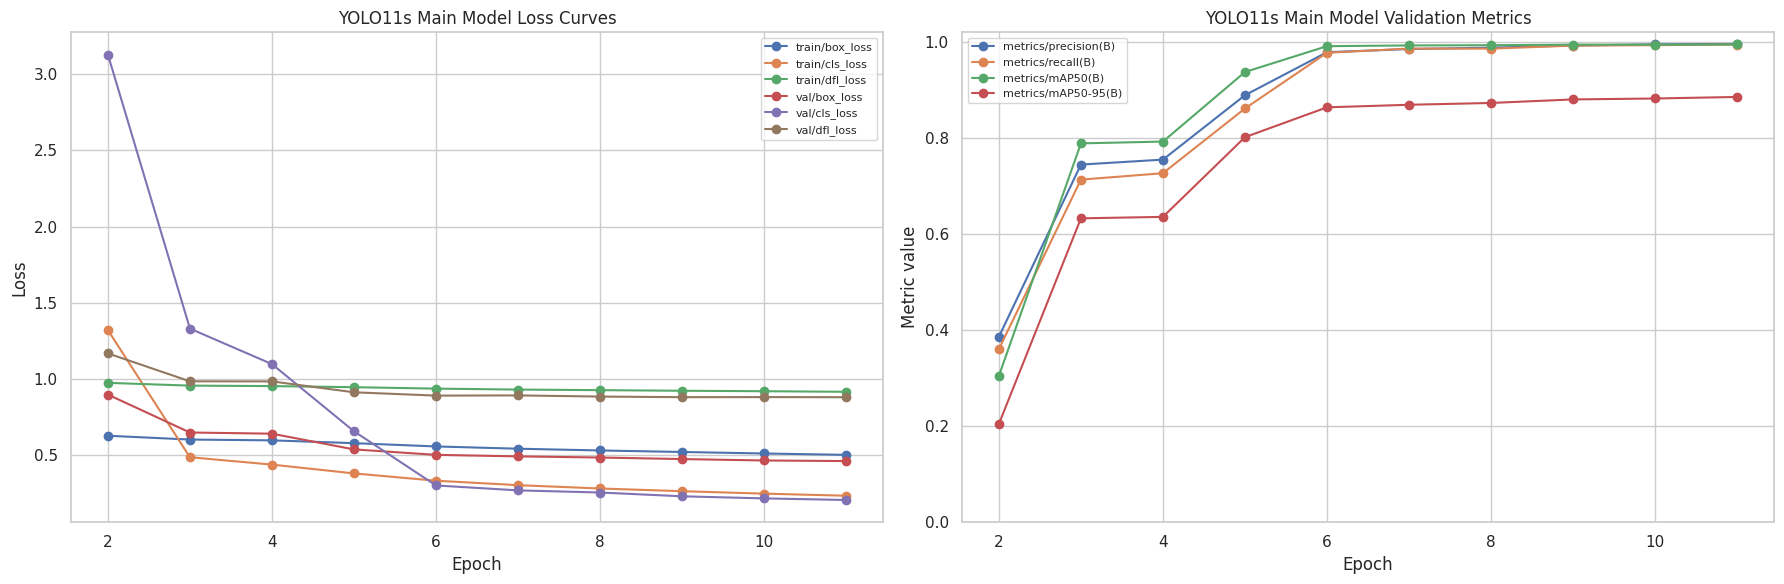

In [11]:
# Read the Ultralytics history file produced during training
# Plot losses separately from validation quality metrics for easier interpretation
def plot_training_history(run_name, title):
    # Locate the epoch history saved by the matching training run
    results_path = RUNS_ROOT / run_name / "results.csv"
    if not results_path.exists():
        print(f"Training history not found: {results_path}")
        return

    # Remove padding from Ultralytics column names before selection
    history = pd.read_csv(results_path)
    history.columns = history.columns.str.strip()
    epochs = history["epoch"] + 1

    # Collect all training and validation loss series
    loss_columns = [
        column for column in history.columns
        if column.startswith("train/") or column.startswith("val/")
        if column.endswith("_loss")
    ]
    # Collect precision recall and both mAP series
    metric_columns = [
        column for column in history.columns
        if column.startswith("metrics/")
    ]

    # Place optimization losses and quality metrics in separate panels
    figure, axes = plt.subplots(1, 2, figsize=(18, 6))
    for column in loss_columns:
        axes[0].plot(epochs, history[column], marker="o", label=column)
    axes[0].set_title(f"{title} Loss Curves")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(fontsize=8)

    for column in metric_columns:
        axes[1].plot(epochs, history[column], marker="o", label=column)
    axes[1].set_title(f"{title} Validation Metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Metric value")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(fontsize=8)

    figure.tight_layout()
    figure.savefig(FIGURES_ROOT / f"{run_name}_training_curves.png", dpi=160)
    plt.show()

plot_training_history(BASELINE_RUN_NAME, "YOLO11n Baseline")
plot_training_history(MAIN_RUN_NAME, "YOLO11s Main Model")

## 10. Detection evaluation

Validation data supports model analysis. The frozen checkpoints are then evaluated on the custom test split.

In [12]:
# Evaluate each frozen checkpoint on the untouched custom test split
# Ultralytics reports average GPU inference time for every processed image
def evaluate_detector(model, method_name):
    # Run one final evaluation without changing model weights
    metrics = model.val(
        data=str(CUSTOM_ROOT / "data.yaml"),
        split="test",
        imgsz=IMGSZ,
        batch=INFERENCE_BATCH,
        device=DEVICE,
        plots=True,
        verbose=False,
    )

    # Read the mean model forward time reported by Ultralytics
    inference_ms = float(metrics.speed["inference"])

    # Return only the measures used in the final comparison
    return {
        "Method": method_name,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP@0.5": float(metrics.box.map50),
        "mAP@0.5:0.95": float(metrics.box.map),
        "Average inference ms": inference_ms,
    }

baseline_detection = evaluate_detector(
    baseline_model, "YOLO11n Baseline"
)
torch.cuda.empty_cache()
main_detection = evaluate_detector(
    main_model, "YOLO11s Main Model"
)
torch.cuda.empty_cache()

Ultralytics 8.4.126 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 48508MiB)
YOLO11n summary (fused): 101 layers, 2,677,888 parameters, 0 gradients, 6.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3301.8±486.7 MB/s, size: 195.8 KB)
val: Scanning /root/autodl-tmp/retail_product_checkout/custom_checkout_dataset/labels/test.cache... 3045 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3045/3045 608.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 191/191 19.8it/s 9.7s0.0s
                   all       3045      36957      0.995      0.994      0.995      0.877
Speed: 0.5ms preprocess, 0.7ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /root/autodl-tmp/runs/detect/val-7
Ultralytics 8.4.126 🚀 Python-3.12.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4090, 48508MiB)
YOLO11s summary (fused): 101 layers, 9,490,200 parameters, 0 gradients, 21.8 GFLOPs
val: Fast imag

## 11. Checkout accuracy

Checkout accuracy is strict. An image is correct only when the predicted count of every SKU exactly matches the ground-truth count. The confidence threshold is selected on the validation split and applied once to the test split.

In [13]:
# Compare complete SKU count vectors rather than isolated detections
# A checkout image is correct only when every product quantity matches
def ground_truth_counts(record):
    # Count every ground-truth SKU instance in the checkout image
    return Counter(
        category_to_yolo[annotation["category_id"]]
        for annotation in record["annotations"]
    )

def predicted_counts(result, confidence):
    # Treat a missing detection list as an empty checkout
    if result.boxes is None:
        return Counter()

    # Move predicted classes and scores to CPU for count comparison
    classes = result.boxes.cls.cpu().numpy().astype(int)
    scores = result.boxes.conf.cpu().numpy()
    # Ignore detections below the confidence being evaluated
    return Counter(classes[scores >= confidence].tolist())

def evaluate_count_accuracy(model, split_records, confidences, description):
    # Track strict checkout success and count error for every threshold
    exact_images = {confidence: 0 for confidence in confidences}
    absolute_errors = {confidence: 0 for confidence in confidences}
    progress = tqdm(total=len(split_records), desc=description)

    # Process small batches to keep GPU memory usage stable
    for start in range(0, len(split_records), INFERENCE_BATCH):
        batch_records = split_records[start:start + INFERENCE_BATCH]
        # Run inference once at the lowest threshold for later filtering
        predictions = model.predict(
            source=[str(record["source"]) for record in batch_records],
            imgsz=IMGSZ,
            batch=INFERENCE_BATCH,
            conf=min(confidences),
            iou=0.6,
            device=DEVICE,
            stream=True,
            verbose=False,
        )

        # Compare every prediction with the complete ground-truth count vector
        for record, prediction_result in zip(batch_records, predictions):
            truth = ground_truth_counts(record)
            # Reuse the same detections across all candidate thresholds
            for confidence in confidences:
                prediction = predicted_counts(prediction_result, confidence)
                exact_images[confidence] += prediction == truth
                absolute_errors[confidence] += sum(
                    abs(prediction.get(class_id, 0) - truth.get(class_id, 0))
                    for class_id in set(prediction) | set(truth)
                )
            progress.update(1)

    progress.close()

    # Convert accumulated totals into per-image evaluation measures
    return pd.DataFrame([
        {
            "Confidence": confidence,
            "cAcc": exact_images[confidence] / len(split_records),
            "Mean count error": absolute_errors[confidence] / len(split_records),
        }
        for confidence in confidences
    ])

def checkout_metrics(model, method_name):
    # Find the operating threshold using validation images only
    validation_results = evaluate_count_accuracy(
        model,
        splits["val"],
        CONFIDENCE_CANDIDATES,
        f"{method_name} validation",
    )
    # Prefer higher checkout accuracy then lower count error
    best_row = validation_results.sort_values(
        ["cAcc", "Mean count error"],
        ascending=[False, True],
    ).iloc[0]
    confidence = float(best_row["Confidence"])

    # Apply the selected threshold once to the untouched test split
    test_results = evaluate_count_accuracy(
        model,
        splits["test"],
        [confidence],
        f"{method_name} test",
    )
    test_row = test_results.iloc[0]

    return {
        "Confidence": confidence,
        "cAcc": float(test_row["cAcc"]),
        "Mean count error": float(test_row["Mean count error"]),
    }, validation_results

baseline_checkout, baseline_thresholds = checkout_metrics(
    baseline_model, "YOLO11n Baseline"
)
torch.cuda.empty_cache()
main_checkout, main_thresholds = checkout_metrics(
    main_model, "YOLO11s Main Model"
)
torch.cuda.empty_cache()

# Save threshold details for reproducibility without displaying extra columns
threshold_table = pd.concat([
    baseline_thresholds.assign(Method="YOLO11n Baseline"),
    main_thresholds.assign(Method="YOLO11s Main Model"),
], ignore_index=True)
threshold_table.to_csv(FIGURES_ROOT / "validation_confidence_selection.csv", index=False)

YOLO11n Baseline validation:   0%|          | 0/2970 [00:00<?, ?it/s]

YOLO11n Baseline test:   0%|          | 0/3045 [00:00<?, ?it/s]

YOLO11s Main Model validation:   0%|          | 0/2970 [00:00<?, ?it/s]

YOLO11s Main Model test:   0%|          | 0/3045 [00:00<?, ?it/s]

## 12. Baseline and main model comparison

The table reports the main detection scores, strict checkout accuracy and average GPU inference time.

,Method,Precision,Recall,mAP@0.5,mAP@0.5:0.95,cAcc,Average inference ms
0,YOLO11n Baseline,0.9951,0.9939,0.9946,0.8774,0.9294,0.7260
1,YOLO11s Main Model,0.9954,0.9956,0.9948,0.8869,0.9491,1.4308


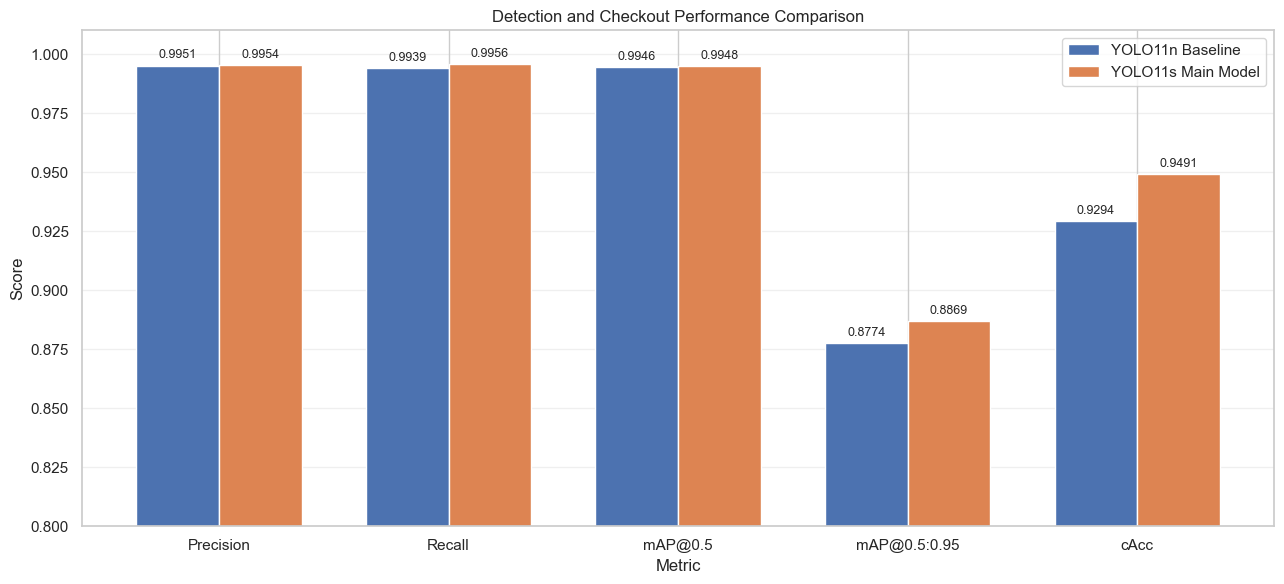

In [14]:
# Combine the important detection and checkout measures in one compact table
# Use the same score scale for the grouped performance chart
# Merge detector quality and strict checkout accuracy for each method
comparison = pd.DataFrame([
    {**baseline_detection, **baseline_checkout},
    {**main_detection, **main_checkout},
])

column_order = [
    "Method",
    "Precision",
    "Recall",
    "mAP@0.5",
    "mAP@0.5:0.95",
    "cAcc",
    "Average inference ms",
]
# Keep only the measures required in the report
comparison = comparison[column_order]
comparison.to_csv(FIGURES_ROOT / "baseline_main_comparison.csv", index=False)
display(comparison.round(4))

# Draw the main quality scores on one shared scale
performance_metrics = [
    "Precision",
    "Recall",
    "mAP@0.5",
    "mAP@0.5:0.95",
    "cAcc",
]
metric_positions = np.arange(len(performance_metrics))
bar_width = 0.36

# Offset the bars so both models remain visible for every metric
figure, axis = plt.subplots(figsize=(13, 6))
baseline_bars = axis.bar(
    metric_positions - bar_width / 2,
    comparison.loc[0, performance_metrics].astype(float),
    bar_width,
    label=comparison.loc[0, "Method"],
    color="#4C72B0",
)
main_bars = axis.bar(
    metric_positions + bar_width / 2,
    comparison.loc[1, performance_metrics].astype(float),
    bar_width,
    label=comparison.loc[1, "Method"],
    color="#DD8452",
)

axis.set_title("Detection and Checkout Performance Comparison")
axis.set_xlabel("Metric")
axis.set_ylabel("Score")
axis.set_xticks(metric_positions)
axis.set_xticklabels(performance_metrics)
axis.set_ylim(0.80, 1.01)
axis.legend()
axis.grid(axis="y", alpha=0.3)
axis.bar_label(baseline_bars, fmt="%.4f", padding=3, fontsize=9)
axis.bar_label(main_bars, fmt="%.4f", padding=3, fontsize=9)

# Save a publication-ready copy of the grouped chart
figure.tight_layout()
figure.savefig(
    FIGURES_ROOT / "baseline_main_grouped_metrics.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

## 13. Five-image automatic checkout demonstration

Five deterministic test images are displayed with English product labels, quantities, simulated prices, line totals and total amounts.

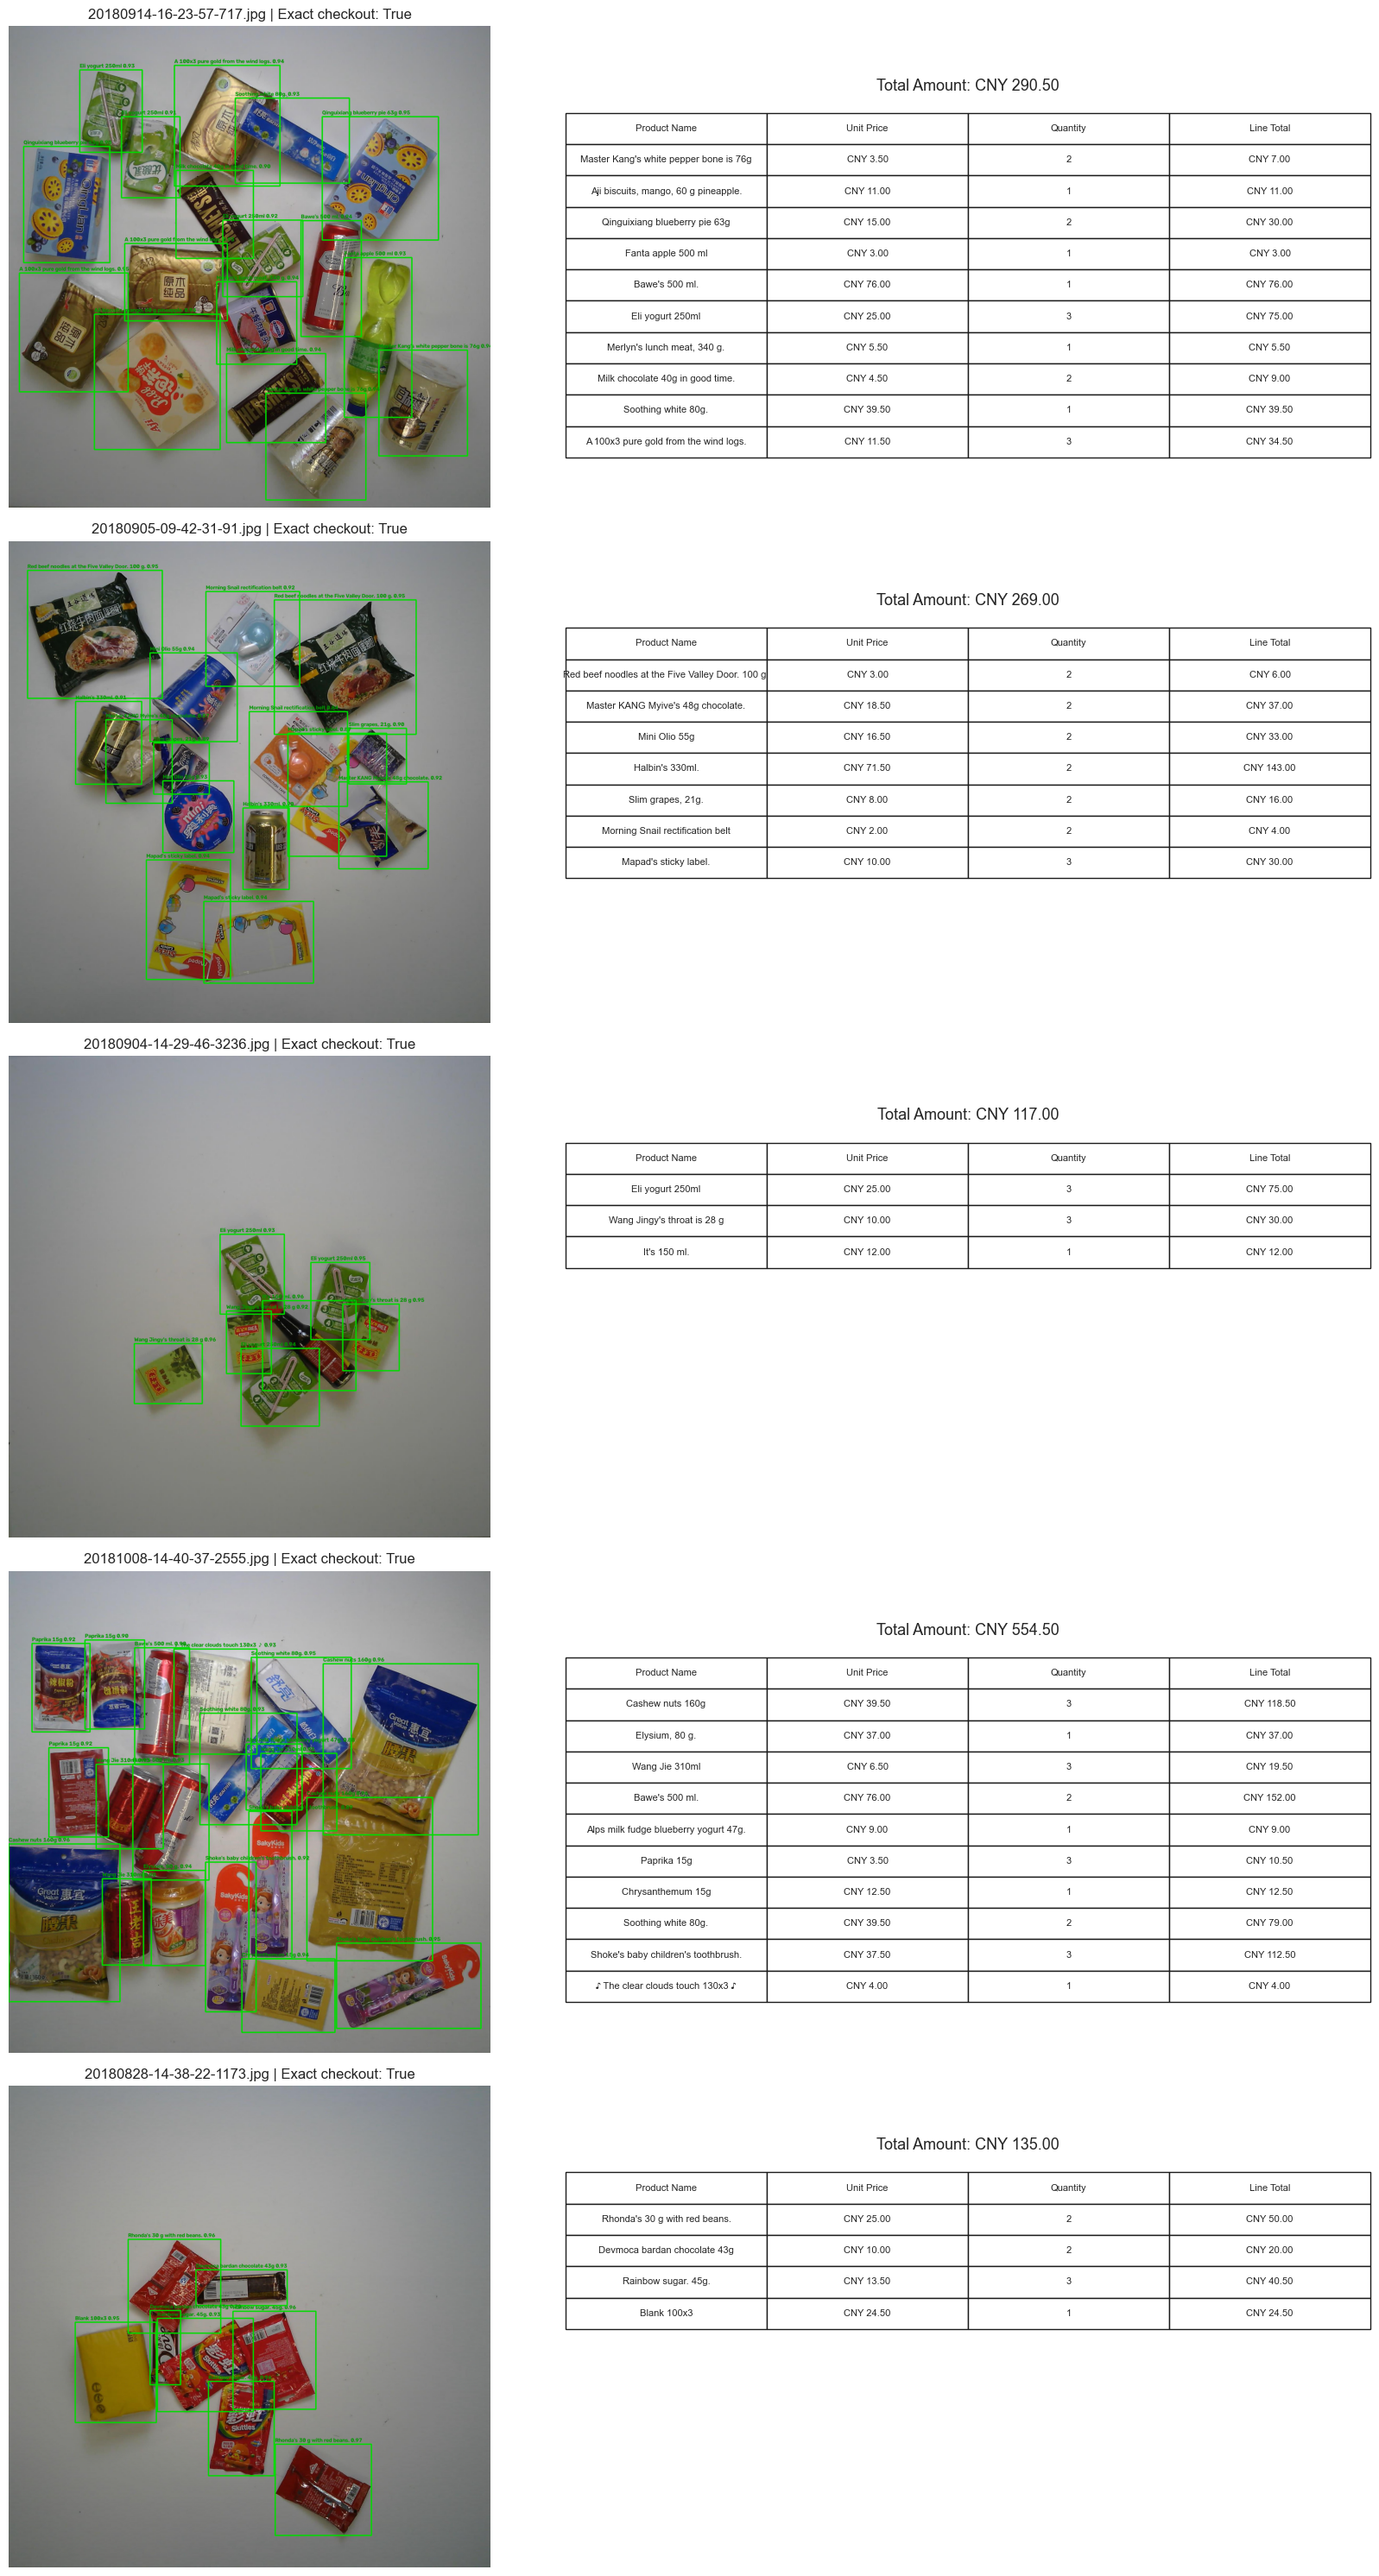

In [15]:
# Load English display names and stable simulated prices for checkout
# Aggregate repeated detections into receipt quantities and line totals
price_table = pd.read_csv(ROOT / "product_prices.csv")
name_table = pd.read_csv(ROOT / "product_name_mapping.csv")
price_by_category = price_table.set_index("category_id")["unit_price"].to_dict()
name_by_category = name_table.set_index("category_id")["product_name_en"].to_dict()

def predict_checkout(model, record, confidence):
    # Run the selected main model on one full checkout image
    result = model.predict(
        source=str(record["source"]),
        imgsz=IMGSZ,
        conf=confidence,
        iou=0.6,
        device=DEVICE,
        verbose=False,
    )[0]
    # Reload the source image for custom English box labels
    image = cv2.imread(str(record["source"]))
    detected_categories = []

    # Draw every accepted detection and retain its SKU identifier
    if result.boxes is not None:
        boxes = result.boxes.xyxy.cpu().numpy().astype(int)
        classes = result.boxes.cls.cpu().numpy().astype(int)
        scores = result.boxes.conf.cpu().numpy()

        for box, class_index, score in zip(boxes, classes, scores):
            category_id = categories[class_index]["id"]
            product_name = str(
                name_by_category.get(category_id, categories[class_index]["name"])
            )
            x1, y1, x2, y2 = box.tolist()
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 220, 0), 4)
            cv2.putText(
                image,
                f"{product_name} {score:.2f}",
                (x1, max(30, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 150, 0),
                2,
                cv2.LINE_AA,
            )
            detected_categories.append(category_id)

    # Group repeated SKU identifiers into receipt quantities
    receipt_rows = []
    for category_id, quantity in sorted(Counter(detected_categories).items()):
        unit_price = float(price_by_category[category_id])
        receipt_rows.append({
            "Product Name": name_by_category[category_id],
            "Unit Price": unit_price,
            "Quantity": quantity,
            "Line Total": unit_price * quantity,
        })

    # Check whether the complete predicted receipt matches the annotation
    receipt = pd.DataFrame(receipt_rows)
    predicted = Counter(category_to_yolo[category_id] for category_id in detected_categories)
    exact_checkout = predicted == ground_truth_counts(record)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB), receipt, exact_checkout

# Select the same five test images on every notebook run
example_records = random.Random(SEED).sample(splits["test"], 5)
main_confidence = float(main_checkout["Confidence"])
figure, axes = plt.subplots(5, 2, figsize=(18, 30))

# Render each annotated image beside its English checkout receipt
for index, record in enumerate(example_records, start=1):
    annotated_image, receipt, exact_checkout = predict_checkout(
        main_model, record, main_confidence
    )
    total_amount = receipt["Line Total"].sum() if not receipt.empty else 0.0

    # Save the receipt and annotated image as separate reusable files
    receipt.to_csv(EXAMPLES_ROOT / f"checkout_{index}.csv", index=False)
    cv2.imwrite(
        str(EXAMPLES_ROOT / f"checkout_{index}_annotated.jpg"),
        cv2.cvtColor(annotated_image, cv2.COLOR_RGB2BGR),
    )

    axes[index - 1, 0].imshow(annotated_image)
    axes[index - 1, 0].set_title(
        f"{record['file_name']} | Exact checkout: {exact_checkout}"
    )
    axes[index - 1, 0].axis("off")
    axes[index - 1, 1].axis("off")

    if receipt.empty:
        axes[index - 1, 1].text(
            0.5, 0.5, "No products detected", ha="center", va="center"
        )
    else:
        display_receipt = receipt.copy()
        display_receipt["Unit Price"] = display_receipt["Unit Price"].map(
            lambda value: f"CNY {value:.2f}"
        )
        display_receipt["Line Total"] = display_receipt["Line Total"].map(
            lambda value: f"CNY {value:.2f}"
        )
        # Keep the receipt close to the total while adapting to row count
        table_height = min(0.76, 0.065 * (len(display_receipt) + 1))
        table_bottom = 0.82 - table_height
        receipt_plot = axes[index - 1, 1].table(
            cellText=display_receipt.values,
            colLabels=display_receipt.columns,
            cellLoc="center",
            bbox=[0.0, table_bottom, 1.0, table_height],
        )
        receipt_plot.auto_set_font_size(False)
        receipt_plot.set_fontsize(8)
        receipt_plot.scale(1, 1.5)

    # Place the bold total directly above the receipt
    axes[index - 1, 1].text(
        0.5,
        0.86,
        f"Total Amount: CNY {total_amount:.2f}",
        transform=axes[index - 1, 1].transAxes,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
    )

# Save a publication-ready copy of the grouped chart
# Save all five checkout examples in one high-resolution figure
figure.tight_layout()
figure.savefig(
    EXAMPLES_ROOT / "five_checkout_examples.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

## 14. Final results

In [16]:
# Print a compact final summary that remains readable after notebook export
print("Custom multi-product split")
print(split_summary.round(2).to_string(index=False))
print("\nBaseline and main model comparison")
print(comparison.round(4).to_string(index=False))
print(f"\nFigures saved to: {FIGURES_ROOT}")
print(f"Checkout examples saved to: {EXAMPLES_ROOT}")

Custom multi-product split
Split  Images  Instances  Groups  Mean products per image
train   23985     294410   10160                    12.27
  val    2970      36568    1270                    12.31
 test    3045      36957    1270                    12.14

Baseline and main model comparison
            Method  Precision  Recall  mAP@0.5  mAP@0.5:0.95   cAcc  Average inference ms
  YOLO11n Baseline     0.9951  0.9939   0.9946        0.8774 0.9294                0.7260
YOLO11s Main Model     0.9954  0.9956   0.9948        0.8869 0.9491                1.4308

Figures saved to: /root/autodl-tmp/retail_product_checkout/figures/custom_split
Checkout examples saved to: /root/autodl-tmp/retail_product_checkout/runs/custom_split_test/checkout_examples
